# Phase 1 & 2 — Data Collection, Preparation and Exploratory Data Analysis

**Project:** AI-Powered Stock Market Trend & News Sentiment Analyzer

**Dataset source:** Yahoo Finance, downloaded through the `yfinance` package and cached in
`data/stock_data.csv` (free, no API key). Re-run `python -m src.data_loader` to refresh it.

| Symbol | Description | Role |
|---|---|---|
| `^NSEI` | NIFTY 50 index | market index |
| `RELIANCE.NS` | Reliance Industries Ltd | stock |
| `TCS.NS` | Tata Consultancy Services Ltd | stock |

**Phase 1 tasks:** load with pandas → convert `Date` to datetime → sort chronologically →
check missing values → check duplicates → handle invalid values → descriptive statistics →
percentage daily return.

In [1]:
from pathlib import Path
import sys

# make the project root importable no matter where the notebook is started from
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 60)

from src.data_loader import prepare, basic_stats, TICKERS, RAW_CSV

df = prepare()          # load -> clean -> daily return
print(f"raw file: {RAW_CSV}")
df.head()

Loaded cached data <- C:\Users\KIIT\Documents\StockMarketAnalyzer\stock_market_ai\data\stock_data.csv

--- Phase 1 cleaning report ---
  missing_before: {}
  duplicate_rows: 0
  missing_after: {}
  rows: 6480
  symbols: ['RELIANCE.NS', 'TCS.NS', '^NSEI']
  date_min: 2018-01-01
  date_max: 2026-09-28
raw file: C:\Users\KIIT\Documents\StockMarketAnalyzer\stock_market_ai\data\stock_data.csv


,Date,Close,High,Low,Open,Volume,Symbol,Name,Daily_Return
0,2018-01-01,400.02,405.71,399.03,405.71,"9,453,202.00",RELIANCE.NS,Reliance Industries,NaN
1,2018-01-02,400.63,404.32,398.54,401.44,"9,499,419.00",RELIANCE.NS,Reliance Industries,0.15
2,2018-01-03,402.24,407.16,401.47,406.72,"13,507,800.00",RELIANCE.NS,Reliance Industries,0.40
3,2018-01-04,404.65,405.31,402.63,403.71,"9,008,932.00",RELIANCE.NS,Reliance Industries,0.60
4,2018-01-05,405.95,407.56,404.63,405.31,"7,441,284.00",RELIANCE.NS,Reliance Industries,0.32


## Phase 1 — cleaning report

Implemented in `src/data_loader.py`:

1. **Load** with pandas.
2. **`Date` → datetime** (timezone stripped, Yahoo returns tz-aware stamps).
3. **Sorted** by Symbol then Date, so every instrument is chronological.
4. **Missing values** counted per column before cleaning.
5. **Duplicates** on `(Symbol, Date)` removed.
6. **Invalid values** — non-positive prices and non-positive volume are treated as missing;
   prices are forward-filled then back-filled *inside each symbol*, volume forward-filled.
7. **Basic statistics** through `.describe()`.
8. **Percentage daily return** = `(Close[t] − Close[t−1]) / Close[t−1] × 100`.

In [2]:
report = pd.Series({
    "rows": len(df),
    "instruments": df["Symbol"].nunique(),
    "date range": f"{df['Date'].min().date()} -> {df['Date'].max().date()}",
    "missing values left": int(df.isna().sum().sum()),
    "duplicate (Symbol, Date) rows": int(df.duplicated(subset=["Symbol", "Date"]).sum()),
    "zero-volume sessions repaired": int((df["Volume"] == 0).sum()),
})
report

rows                                                 6480
instruments                                             3
date range                       2018-01-01 -> 2026-09-28
missing values left                                     3
duplicate (Symbol, Date) rows                           0
zero-volume sessions repaired                           0
dtype: object

In [3]:
# 7. basic statistical information about the dataset
basic_stats(df)

Open                                                  \
               count      mean      std      min       25%       50%   
Symbol                                                                 
RELIANCE.NS 2,163.00  1,020.64   342.04   385.62    674.60  1,106.93   
TCS.NS      2,163.00  2,622.24   775.98 1,057.98  1,841.04  2,814.26   
^NSEI       2,154.00 17,360.06 5,407.77 7,735.15 11,657.91 17,403.30   

                                    High                              \
                  75%       max    count      mean      std      min   
Symbol                                                                 
RELIANCE.NS  1,289.72  1,585.67 2,163.00  1,030.53   344.09   393.90   
TCS.NS       3,168.09  4,251.38 2,163.00  2,647.02   780.83 1,070.03   
^NSEI       23,032.94 26,333.70 2,154.00 17,439.88 5,423.79 8,036.95   

                                                         Low            \
                  25%       50%       75%       max    count      mean   
Symbol                                                                   
RELIANCE.NS    683.29  1,119.18  1,301.53  1,604.38 2,163.00  1,010.23   
TCS.NS       1,855.43  2,842.62  3,190.99  4,266.48 2,163.00  2,595.88   
^NSEI       11,707.56 17,471.08 23,143.01 26,373.20 2,154.00 17,257.13   

                                                                       \
                 std      min       25%       50%       75%       max   
Symbol                                                                  
RELIANCE.NS   340.02   382.98    668.61  1,096.48  1,277.14  1,570.94   
TCS.NS        771.19 1,053.23  1,820.37  2,786.65  3,136.10  4,191.92   
^NSEI       5,394.34 7,511.10 11,578.81 17,295.33 22,814.32 26,210.05   

               Close                                                  \
               count      mean      std      min       25%       50%   
Symbol                                                                 
RELIANCE.NS 2,163.00  1,019.99   341.94   388.12    672.48  1,106.02   
TCS.NS      2,163.00  2,620.69   775.71 1,057.65  1,836.11  2,817.52   
^NSEI       2,154.00 17,350.42 5,408.82 7,610.25 11,649.96 17,381.00   

                                  Volume                              \
                  75%       max    count          mean           std   
Symbol                                                                 
RELIANCE.NS  1,290.68  1,584.97 2,163.00 17,946,437.04 13,519,293.73   
TCS.NS       3,163.24  4,230.71 2,163.00  2,938,919.74  2,595,699.44   
^NSEI       22,958.94 26,328.55 2,154.00    378,263.65    185,687.08   

                                                                    \
                     min           25%           50%           75%   
Symbol                                                               
RELIANCE.NS 1,705,656.00 10,127,309.00 14,084,409.00 20,780,107.50   
TCS.NS        144,530.00  1,790,965.50  2,468,272.00  3,403,382.50   
^NSEI             100.00    251,700.00    315,450.00    458,600.00   

                            
                       max  
Symbol                      
RELIANCE.NS 142,683,366.00  
TCS.NS       88,067,154.00  
^NSEI         1,811,000.00

In [4]:
# 8. percentage daily return per stock
daily = df.pivot_table(index="Date", columns="Symbol", values="Daily_Return")
daily.round(2).head()

Symbol,RELIANCE.NS,TCS.NS,^NSEI
Date,,,
2018-01-02,0.15,-0.54,NaN
2018-01-03,0.40,0.28,0.01
2018-01-04,0.60,0.70,0.59
2018-01-05,0.32,1.21,0.51
2018-01-08,0.57,0.94,0.61


---

## Phase 2 — Exploratory Data Analysis

The five required views: closing price, trading volume, daily returns, price volatility and
a cross-stock comparison, followed by the written answers A–E.

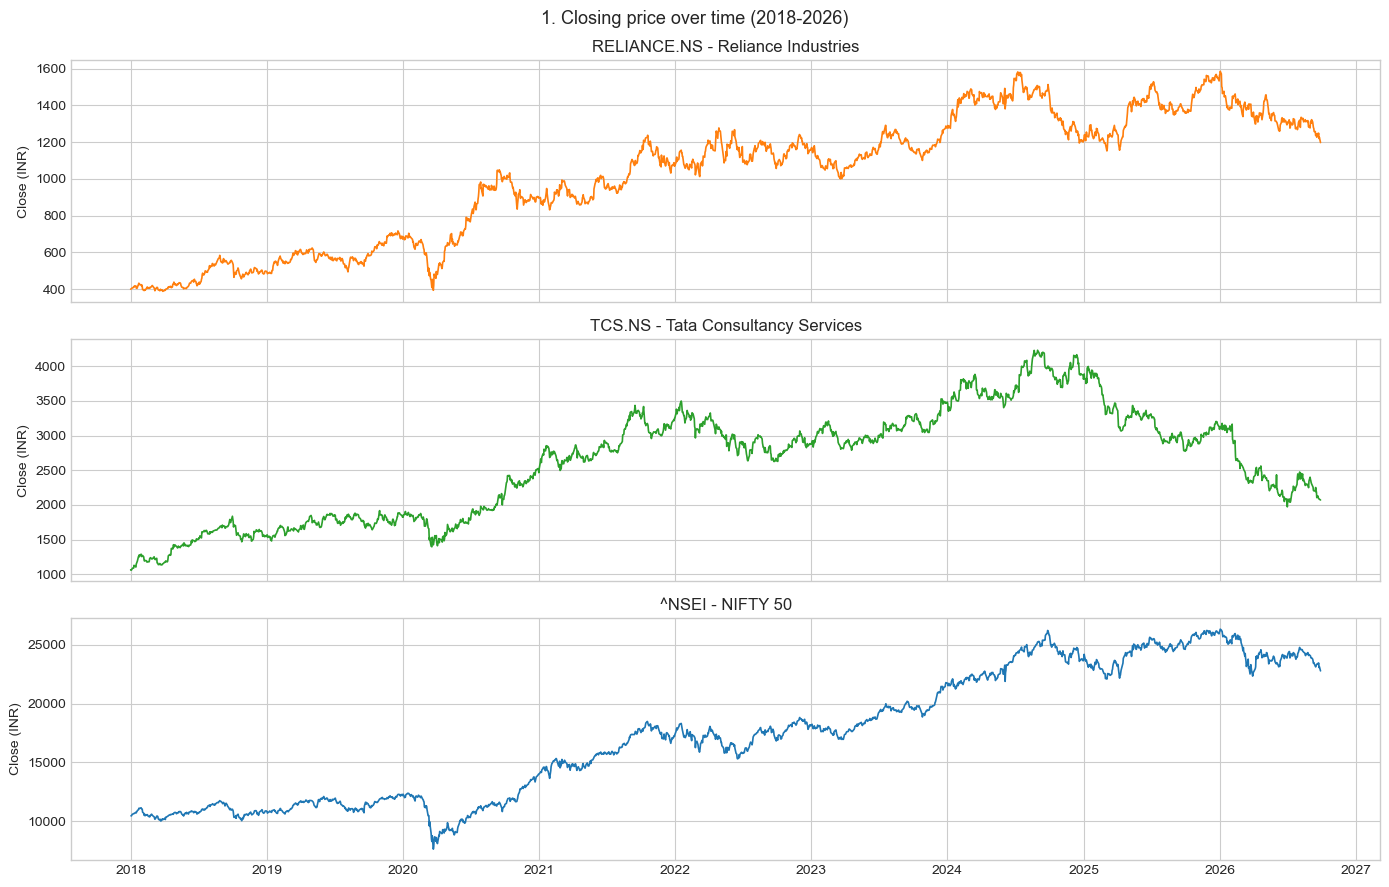

In [5]:
colors = {"^NSEI": "#1f77b4", "RELIANCE.NS": "#ff7f0e", "TCS.NS": "#2ca02c"}

# 1. Closing price over time
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, (sym, part) in zip(axes, df.groupby("Symbol")):
    ax.plot(part["Date"], part["Close"], lw=1.2, color=colors.get(sym, "grey"))
    ax.set_ylabel("Close (INR)")
    ax.set_title(f"{sym} - {part['Name'].iloc[0]}")
fig.suptitle("1. Closing price over time (2018-2026)", fontsize=13)
fig.tight_layout()

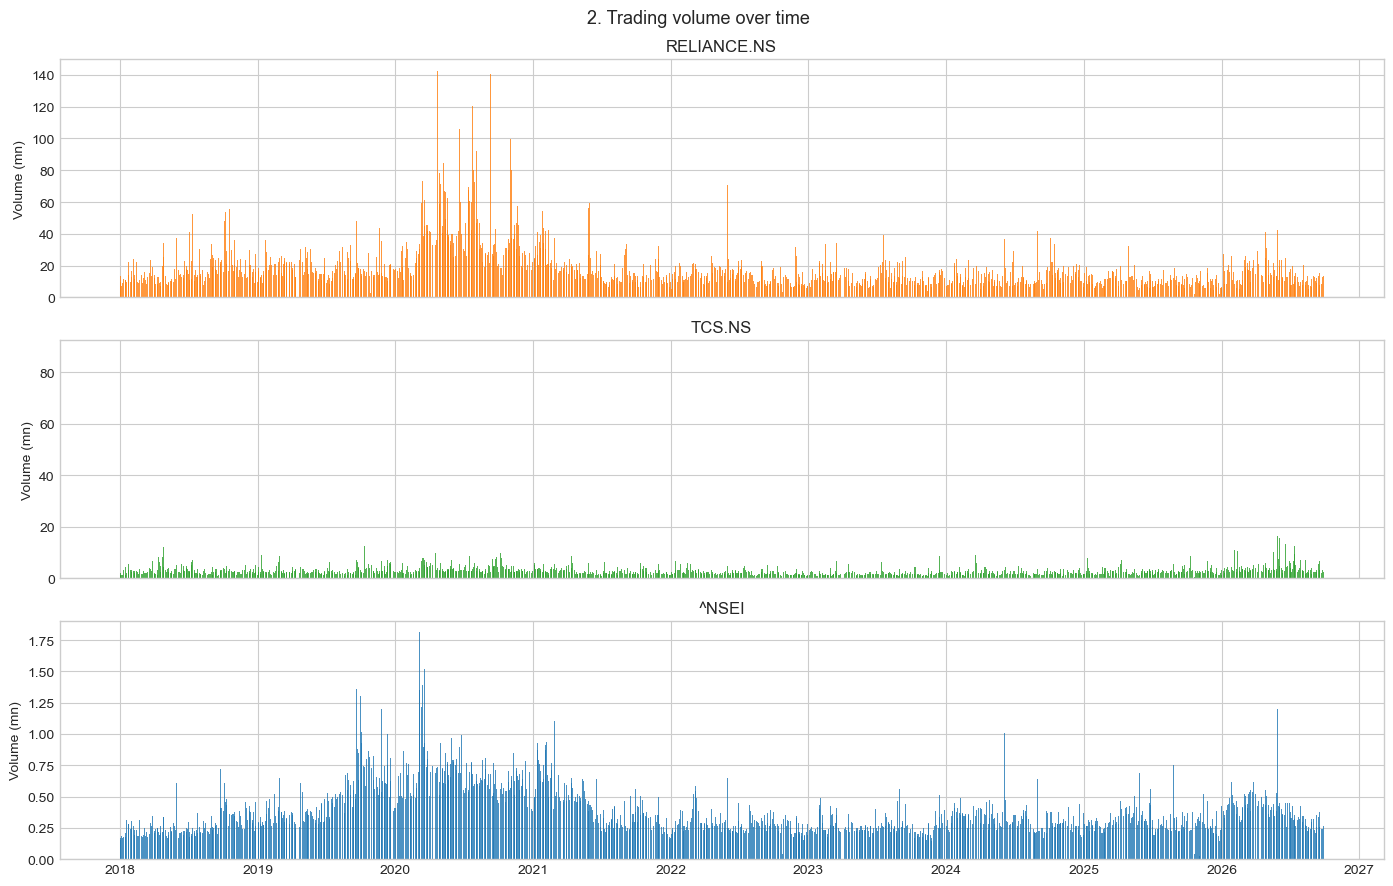

In [6]:
# 2. Trading volume over time
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, (sym, part) in zip(axes, df.groupby("Symbol")):
    ax.bar(part["Date"], part["Volume"] / 1e6, width=1.4,
           color=colors.get(sym, "grey"), alpha=0.8)
    ax.set_ylabel("Volume (mn)")
    ax.set_title(sym)
fig.suptitle("2. Trading volume over time", fontsize=13)
fig.tight_layout()

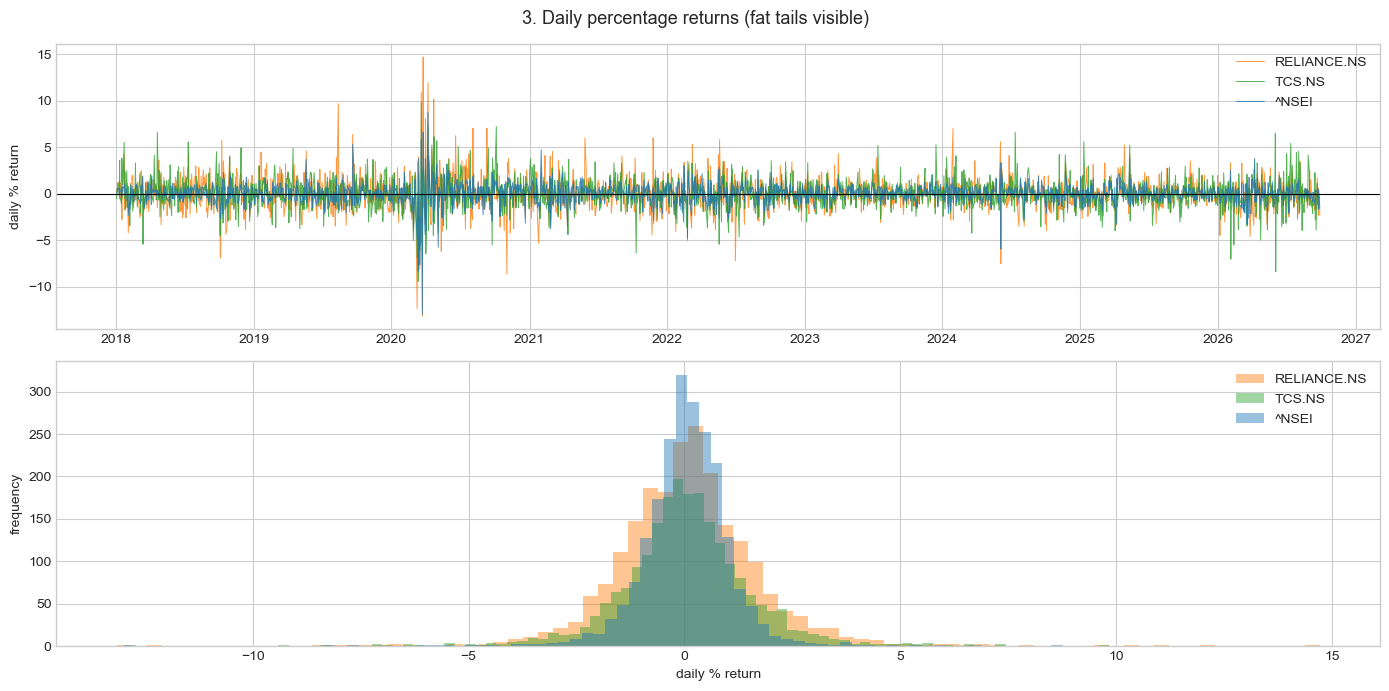

In [7]:
# 3. Daily percentage returns
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for sym, part in df.groupby("Symbol"):
    axes[0].plot(part["Date"], part["Daily_Return"], lw=0.7,
                 color=colors.get(sym, "grey"), alpha=0.8, label=sym)
    axes[1].hist(part["Daily_Return"].dropna(), bins=80, alpha=0.45,
                 color=colors.get(sym, "grey"), label=sym)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylabel("daily % return"); axes[0].legend()
axes[1].set_xlabel("daily % return"); axes[1].set_ylabel("frequency"); axes[1].legend()
fig.suptitle("3. Daily percentage returns (fat tails visible)", fontsize=13)
fig.tight_layout()

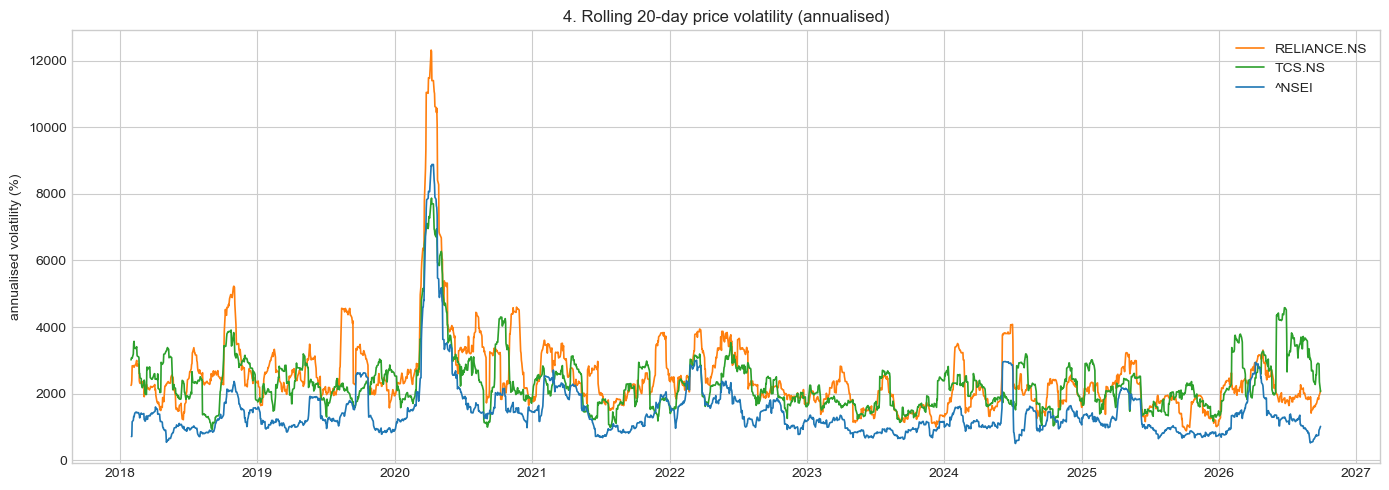

In [8]:
# 4. Price volatility - 20-day rolling standard deviation of returns, annualised
fig, ax = plt.subplots(figsize=(14, 5))
for sym, part in df.groupby("Symbol"):
    part = part.sort_values("Date")
    roll = part["Daily_Return"].rolling(20).std() * np.sqrt(252)
    ax.plot(part["Date"], roll * 100, lw=1.2, color=colors.get(sym, "grey"), label=sym)
ax.set_ylabel("annualised volatility (%)")
ax.set_title("4. Rolling 20-day price volatility (annualised)")
ax.legend(); fig.tight_layout()

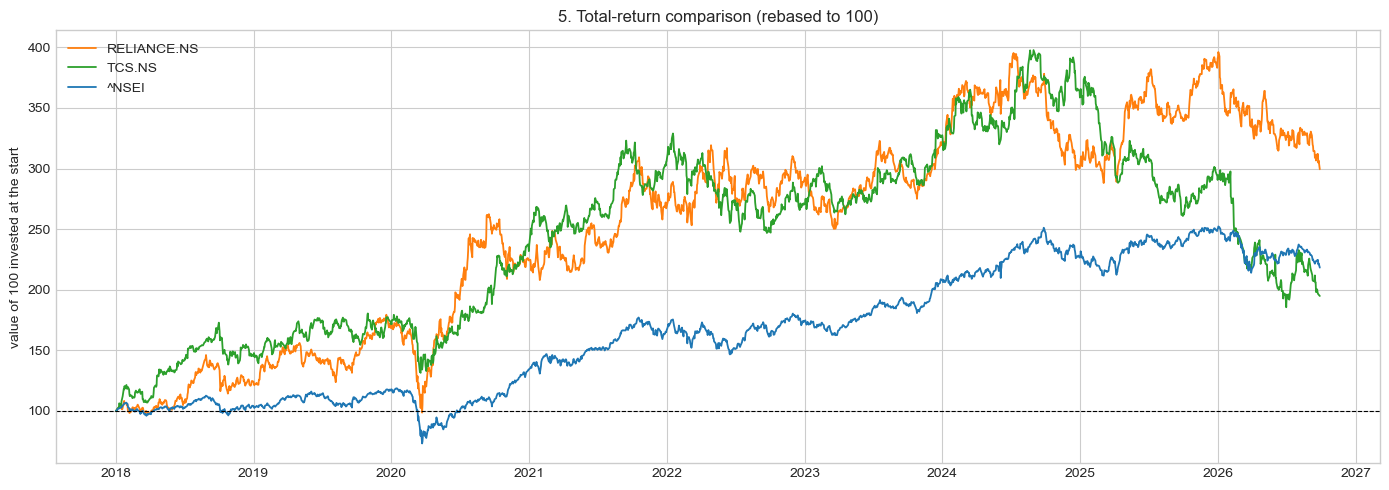

In [9]:
# 5. Comparison of the selected stocks, rebased to 100
fig, ax = plt.subplots(figsize=(14, 5))
for sym, part in df.groupby("Symbol"):
    part = part.sort_values("Date")
    ax.plot(part["Date"], 100 * part["Close"] / part["Close"].iloc[0],
            lw=1.3, color=colors.get(sym, "grey"), label=sym)
ax.axhline(100, color="black", lw=0.8, ls="--")
ax.set_ylabel("value of 100 invested at the start")
ax.set_title("5. Total-return comparison (rebased to 100)")
ax.legend(); fig.tight_layout()

In [10]:
# numbers behind answers A and B
summary = pd.DataFrame({
    "ann. volatility %": df.groupby("Symbol")["Daily_Return"].std() * np.sqrt(252),
    "mean |daily return| %": df.groupby("Symbol")["Daily_Return"].apply(lambda s: s.abs().mean()),
    "worst day %": df.groupby("Symbol")["Daily_Return"].min(),
    "best day %": df.groupby("Symbol")["Daily_Return"].max(),
    "total return %": df.groupby("Symbol")["Close"].apply(
        lambda s: (s.iloc[-1] / s.iloc[0] - 1) * 100),
}).round(2)
summary.sort_values("ann. volatility %", ascending=False)

,ann. volatility %,mean |daily return| %,worst day %,best day %,total return %
Symbol,,,,,
RELIANCE.NS,27.48,1.20,-13.15,14.72,199.39
TCS.NS,24.65,1.10,-9.41,9.85,94.72
^NSEI,16.88,0.71,-12.98,8.76,118.16


In [11]:
# volume vs price movement (answer D) and the spike calendar (answer C)
rows = []
for sym, part in df.groupby("Symbol"):
    thresh = part["Volume"].quantile(0.90)
    hi = part.loc[part["Volume"] >= thresh, "Daily_Return"].abs().median()
    lo = part.loc[part["Volume"] < thresh, "Daily_Return"].abs().median()
    rows.append({"Symbol": sym,
                 "corr(volume, |return|)": part["Volume"].corr(part["Daily_Return"].abs()),
                 "median |return| high-volume %": hi,
                 "median |return| other days %": lo,
                 "ratio": hi / lo})
vol_vs_move = pd.DataFrame(rows).set_index("Symbol").round(3)
display(vol_vs_move)

spikes = (df.sort_values(["Symbol", "Volume"], ascending=[True, False])
            .groupby("Symbol").head(5)
            .sort_values(["Symbol", "Date"])[["Symbol", "Date", "Volume", "Daily_Return"]])
display(spikes)

,"corr(volume, |return|)",median |return| high-volume %,median |return| other days %,ratio
Symbol,,,,
RELIANCE.NS,0.52,2.08,0.83,2.49
TCS.NS,0.42,2.03,0.72,2.82
^NSEI,0.37,0.89,0.51,1.77


,Symbol,Date,Volume,Daily_Return
563,RELIANCE.NS,2020-04-22,"142,683,366.00",10.20
565,RELIANCE.NS,2020-04-24,"134,986,308.00",3.36
621,RELIANCE.NS,2020-07-15,"139,669,773.00",-3.81
628,RELIANCE.NS,2020-07-24,"120,597,372.00",4.29
662,RELIANCE.NS,2020-09-10,"140,304,404.00",7.06
2211,TCS.NS,2018-03-13,"88,067,154.00",-5.42
2237,TCS.NS,2018-04-20,"18,465,662.00",6.62
2294,TCS.NS,2018-07-11,"22,903,802.00",5.59
2841,TCS.NS,2020-10-05,"17,412,105.00",7.23
2844,TCS.NS,2020-10-08,"19,839,329.00",3.28


### Phase 2 answers

**A. Which stock shows the highest volatility?**
**Reliance Industries** — annualised volatility **27.5 %**, versus TCS **24.6 %** and the
NIFTY 50 **16.9 %**. The index is the calmest because it diversifies 50 constituents.

**B. Which stock has experienced the largest price movements?**
**Reliance**: widest single-day swing (worst day **−13.15 %**, best day **+14.72 %**),
largest average absolute daily move (**1.20 %** vs 1.10 % for TCS and 0.71 % for NIFTY)
and largest cumulative gain (**+199 %**). TCS moved the least overall (+94.7 % cumulative,
worst day −9.41 %).

**C. Are there periods where unusually high trading volume occurs?**
Yes, and the spikes cluster. All five busiest NIFTY sessions fall in **March 2020**
(COVID-19 crash: 6, 9, 13 and 18 March 2020), Reliance's peak volume days sit in
**April–September 2020** (COVID bottom plus its 2020 stake-sales programme), and TCS
clusters in **March–July 2018** and **October 2020** (results/buyback-related sessions).

**D. Is high trading volume associated with major price movements?**
**Yes.** On the busiest decile of sessions the median absolute daily move is **2.5×
(Reliance), 2.8× (TCS) and 1.8× (NIFTY)** larger than on ordinary days. Reliance's
busiest session ever (22 Apr 2020, 143 mn shares) carried a **+10.2 %** move; TCS's
busiest (13 Mar 2018) a **−5.4 %** move. That is why `Volume_Change` becomes a Phase-4
feature.

**E. Useful observations from the historical data**

* All three instruments trended up over 2018–2026 (NIFTY +118 %, Reliance +199 %,
  TCS +95 %) → the "UP" class is a slight majority, so a naive baseline is competitive.
* Volatility **clusters**: the COVID spike pushed 20-day volatility above 100 % annualised
  for Reliance, many times the calm periods → rolling volatility is a real feature and
  drives the Phase-12 risk label.
* Returns have **fat tails** (±5–14 % days in a sample whose typical day is ~1 %).
* TCS and the NIFTY behave more alike than Reliance does, so index context should help
  predict the two stocks.